# Phase 5 — Baseline Model Interpretation & Customer Churn Business Insights
## AI-Powered Customer Churn & Retention System

### Phase Objective
The objective of Phase 5 is to rigorously translate the baseline modeling results established in Phase 4 into actionable, methodologically sound customer and business insights:
1. **Model Performance Interpretation:** Dissect hold-out test results (Accuracy, Precision, Recall, F1, ROC-AUC), class imbalance effects (~73.46% vs ~26.54%), and why raw accuracy is misleading.
2. **Confusion Matrix Analysis:** Quantify True Positives, True Negatives, False Positives, and False Negatives, explaining the asymmetric business cost of False Negatives (silent customer defection) versus False Positives.
3. **Feature & Churn Driver Analysis:** Conduct exploratory and model-based feature association analysis (Contract, Tenure, Monthly Charges, Internet Service, Payment Method, Bundled Services) strictly adhering to **non-causal** statistical interpretation.
4. **Diagnostic & Exploratory Visualizations:** Present publication-ready visual artifacts saved in `reports/figures/`.
5. **Business Interpretation & Limitations:** Profile high-risk and low-risk customer segments, outline structural limitations, and define boundaries before moving to model tuning or retention strategy.

> **Methodological Note (Non-Causal Disclaimer):**  
> All feature importance metrics and statistical correlations reflect observational associations within this dataset. Correlation does **NOT** imply causation. We state that *"customers with characteristic $X$ exhibited higher observed churn rates"*, rather than claiming that *$X$ causes customer churn*.

> **Scope Boundaries (Phase 5):**  
> - No hyperparameter optimization (GridSearchCV / RandomizedSearchCV) is performed.  
> - No synthetic oversampling (SMOTE) or threshold tuning is applied.  
> - No final production model is declared or saved.  
> - No automated retention recommendations or Streamlit interfaces are built yet.


In [1]:
# Environment Setup & Library Imports
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Add project root to sys.path
project_root = os.path.abspath(os.path.join(".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.data_preprocessing import (
    get_feature_target_split,
    build_preprocessing_pipeline
)
from src.model_training import (
    create_train_test_split,
    build_models,
    fit_preprocessor_and_transform,
    RANDOM_STATE
)

sns.set_theme(style="whitegrid", palette="muted")
print("Phase 5 environment initialized successfully. RANDOM_STATE =", RANDOM_STATE)


Phase 5 environment initialized successfully. RANDOM_STATE = 42


## 1. Load Processed Data and Baseline Comparison Metrics
We load the cleaned dataset `data/processed/telco_churn_cleaned.csv` and the baseline model metrics table generated in Phase 4 from `reports/model_comparison.csv`.


In [2]:
# Load cleaned dataset
data_path = os.path.join("..", "data", "processed", "telco_churn_cleaned.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "processed", "telco_churn_cleaned.csv")

df = pd.read_csv(data_path)
print(f"Loaded cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")

# Load baseline comparison metrics from Phase 4
comparison_csv_path = os.path.join("..", "reports", "model_comparison.csv")
if not os.path.exists(comparison_csv_path):
    comparison_csv_path = os.path.join("reports", "model_comparison.csv")

comparison_df = pd.read_csv(comparison_csv_path)
print("\nBaseline Model Performance Summary (Hold-out Test Set, N=1,409):")
display(comparison_df)


Loaded cleaned dataset: 7,043 rows x 20 columns

Baseline Model Performance Summary (Hold-out Test Set, N=1,409):


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8420
1,Decision Tree,0.7182,0.4698,0.4786,0.4742,0.6415
2,Random Forest,0.7821,0.6128,0.4866,0.5425,0.8183
3,Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8433
4,XGBoost,0.7764,0.5897,0.5187,0.5519,0.8205


## 2. Model Performance Interpretation

### Metric Definitions and Practical Significance in Churn Prediction

1. **Accuracy (Overall Correctness):**
   $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
   - **Range across baselines:** $71.82\%$ (Decision Tree) to $80.55\%$ (Logistic Regression).
   - **Practical Meaning:** While $80.55\%$ sounds respectable at first glance, accuracy evaluates both classes equally. In customer churn, the majority class (Retained, $73.46\%$) heavily inflates the accuracy score.

2. **Precision (Positive Predictive Value):**
   $$\text{Precision} = \frac{TP}{TP + FP}$$
   - **Range across baselines:** $46.98\%$ (Decision Tree) to $66.55\%$ (Gradient Boosting).
   - **Practical Meaning:** Of all customers flagged as prospective churners, what fraction actually left? Higher precision prevents wasting retention budget and customer goodwill on accounts that had no intention of canceling.

3. **Recall / Sensitivity (Churn Detection Rate):**
   $$\text{Recall} = \frac{TP}{TP + FN}$$
   - **Range across baselines:** $47.86\%$ (Decision Tree) to $55.88\%$ (Logistic Regression).
   - **Practical Meaning:** Of all actual churners, what proportion was successfully caught before defection? In churn management, recall is paramount because an undetected churner cannot be saved.

4. **F1-Score (Harmonic Mean of Precision and Recall):**
   $$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
   - **Range across baselines:** $0.4742$ (Decision Tree) to $0.6040$ (Logistic Regression).
   - **Practical Meaning:** Balances false alerts against missed defections under the default $0.5$ classification threshold.

5. **ROC-AUC (Discrimination Capacity):**
   - **Range across baselines:** $0.6415$ (Decision Tree) to $0.8433$ (Gradient Boosting).
   - **Practical Meaning:** Evaluates the model's ranking ability across *all* possible probability thresholds. An AUC of $0.8433$ indicates that an actual churner has an $84.33\%$ probability of being assigned a higher risk score than a randomly chosen retained customer.

---

### The Class Imbalance Problem: Why Accuracy Alone is Misleading

The target variable distribution is moderately imbalanced:
- **Retained (No):** 5,174 ($73.46\%$)
- **Churned (Yes):** 1,869 ($26.54\%$)

Consider a **naive majority-class dummy classifier** that blindly predicts "No Churn" for every single customer:
- **Dummy Accuracy:** **$73.46\%$**
- **Dummy Recall:** **$0.00\%$** (Zero churners identified)
- **Dummy F1-Score:** **$0.00$**

Notice that:
- **Decision Tree ($71.82\%$ accuracy)** actually performed **worse** than a naive dummy classifier!
- **Logistic Regression ($80.55\%$)** and **Gradient Boosting ($80.27\%$)** only improve upon the naive baseline by roughly $7$ percentage points of accuracy, yet their true value lies in detecting over $50\%$ of churners ($Recall \approx 52\% - 56\%$), which the naive baseline cannot do.
- **Conclusion:** Relying on accuracy alone in churn prediction is actively hazardous. It can lead organizations to deploy models that silently miss the majority of defection events.

> **Phase Boundary Reminder:** We do **not** declare a final production model at this stage. Baseline models are evaluated to establish an un-tuned foundation.


## 3. Confusion Matrix Analysis & Asymmetric Error Costs

### Exact Hold-out Test Set Confusion Matrices (N = 1,409)
Hold-out test ground truth:
- **Actual Retained (Negative Class, 0):** $1,035$ ($73.46\%$)
- **Actual Churned (Positive Class, 1):** $374$ ($26.54\%$)


In [3]:
# Compute and display exact confusion matrix breakdowns
X_train, X_test, y_train, y_test = create_train_test_split(df, target_col="Churn", test_size=0.2, random_state=RANDOM_STATE)
preprocessor = build_preprocessing_pipeline(scale_numeric=True)
X_train_prep, X_test_prep = fit_preprocessor_and_transform(preprocessor, X_train, X_test)

models = build_models(random_state=RANDOM_STATE)
cm_records = []

for name, model in models.items():
    model.fit(X_train_prep, y_train)
    y_pred = model.predict(X_test_prep)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    cm_records.append({
        "Model": name,
        "True Negative (TN)": tn,
        "False Positive (FP)": fp,
        "False Negative (FN)": fn,
        "True Positive (TP)": tp,
        "Precision": round(tp / (tp + fp), 4),
        "Recall": round(tp / (tp + fn), 4),
        "Missed Churners (FN)": f"{fn} / {tp + fn} ({round(fn / (tp + fn) * 100, 1)}%)"
    })

cm_df = pd.DataFrame(cm_records)
display(cm_df)


,Model,True Negative (TN),False Positive (FP),False Negative (FN),True Positive (TP),Precision,Recall,Missed Churners (FN)
0,Logistic Regression,926,109,165,209,0.6572,0.5588,165 / 374 (44.1%)
1,Decision Tree,833,202,195,179,0.4698,0.4786,195 / 374 (52.1%)
2,Random Forest,920,115,192,182,0.6128,0.4866,192 / 374 (51.3%)
3,Gradient Boosting,938,97,181,193,0.6655,0.5160,181 / 374 (48.4%)
4,XGBoost,900,135,180,194,0.5897,0.5187,180 / 374 (48.1%)


### The Business Economics: False Negatives vs. False Positives

In customer churn management, classification errors have profoundly asymmetric financial and operational consequences:

| Error Type | Statistical Definition | Business Consequence | Relative Financial Cost |
| :--- | :--- | :--- | :--- |
| **False Negative (FN)** | Actual Churner predicted as Retained | **Silent Defection:** The customer cancels their subscription without the business ever knowing they were at risk. No intervention is attempted. Customer Lifetime Value (LTV) is permanently forfeited. Replacement requires expensive customer acquisition cost (CAC). | **High / Critical Cost** |
| **False Positive (FP)** | Retained customer predicted as Churner | **Unnecessary Outreach:** A contented, loyal subscriber receives a retention promotion, check-in call, or discount offer. The cost is limited to the marginal operational cost of the message or discount. | **Low / Manageable Cost** |

### Why Minority-Class Recall Matters
Under the baseline default threshold ($p \ge 0.5$):
- **Logistic Regression:** Misses **$165$ out of $374$** churners ($44.1\%$ missed).
- **Decision Tree:** Misses **$195$ out of $374$** churners ($52.1\%$ missed).
- **Random Forest:** Misses **$192$ out of $374$** churners ($51.3\%$ missed).
- **Gradient Boosting:** Misses **$181$ out of $374$** churners ($48.4\%$ missed).
- **XGBoost:** Misses **$180$ out of $374$** churners ($48.1\%$ missed).

> **Core Takeaway:** At the default 0.5 classification threshold, the baseline models missed approximately 44%–52% of actual churners in the hold-out test set (165 to 195 missed accounts out of 374). This indicates that threshold choice may materially affect the recall/business tradeoff and can be investigated in a later phase.


## 4. Feature & Churn Driver Analysis

### Important Methodological Guideline: Association $\neq$ Causation
In observational business datasets, features that correlate strongly with churn do **not** necessarily cause customer departure. 
- **Valid statement:** *"Customers on Month-to-month contracts showed an observed churn rate of $42.7\%$ in this dataset, compared to $2.8\%$ for Two-year contracts."*
- **Invalid statement:** *"Month-to-month contracts cause customers to leave."*

### Empirical Bivariate Churn Distributions
We examine observed churn rates across key contract, tenure, billing, and service dimensions across all 7,043 customers.


In [4]:
# Bivariate summary tables for key customer attributes
def get_churn_breakdown(df, col_name):
    agg = df.groupby(col_name, observed=False)["Churn"].agg(["count", "mean"]).rename(
        columns={"count": "Customer Count", "mean": "Observed Churn Rate"}
    )
    agg["Observed Churn Rate (%)"] = (agg["Observed Churn Rate"] * 100).round(2)
    agg["Segment Share (%)"] = ((agg["Customer Count"] / len(df)) * 100).round(2)
    return agg[["Customer Count", "Segment Share (%)", "Observed Churn Rate (%)"]]

print("1. Churn by Contract Commitment:")
display(get_churn_breakdown(df, "Contract"))

print("\n2. Churn by Internet Service Type:")
display(get_churn_breakdown(df, "InternetService"))

print("\n3. Churn by Payment Method:")
display(get_churn_breakdown(df, "PaymentMethod"))

print("\n4. Churn by Tech Support Subscription:")
display(get_churn_breakdown(df, "TechSupport"))

print("\n5. Churn by Online Security Subscription:")
display(get_churn_breakdown(df, "OnlineSecurity"))


1. Churn by Contract Commitment:


,Customer Count,Segment Share (%),Observed Churn Rate (%)
Contract,,,
Month-to-month,3875,55.02,42.71
One year,1473,20.91,11.27
Two year,1695,24.07,2.83



2. Churn by Internet Service Type:


,Customer Count,Segment Share (%),Observed Churn Rate (%)
InternetService,,,
DSL,2421,34.37,18.96
Fiber optic,3096,43.96,41.89
No,1526,21.67,7.40



3. Churn by Payment Method:


,Customer Count,Segment Share (%),Observed Churn Rate (%)
PaymentMethod,,,
Bank transfer (automatic),1544,21.92,16.71
Credit card (automatic),1522,21.61,15.24
Electronic check,2365,33.58,45.29
Mailed check,1612,22.89,19.11



4. Churn by Tech Support Subscription:


,Customer Count,Segment Share (%),Observed Churn Rate (%)
TechSupport,,,
No,3473,49.31,41.64
No internet service,1526,21.67,7.40
Yes,2044,29.02,15.17



5. Churn by Online Security Subscription:


,Customer Count,Segment Share (%),Observed Churn Rate (%)
OnlineSecurity,,,
No,3498,49.67,41.77
No internet service,1526,21.67,7.40
Yes,2019,28.67,14.61


### Tenure and Monthly Charges Cohort Analysis
Continuous features exhibit strong empirical non-linear patterns when segmented into operational cohorts.


In [5]:
# Tenure Cohorts
df_analysis = df.copy()
df_analysis["Tenure_Cohort"] = pd.cut(
    df_analysis["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months (Year 1)", "13-24 months (Year 2)", "25-48 months (Years 3-4)", "49-72 months (Years 5-6)"]
)
print("6. Churn by Tenure Cohort:")
display(get_churn_breakdown(df_analysis, "Tenure_Cohort"))

# Monthly Charges Quartiles
df_analysis["Monthly_Charges_Quartile"] = pd.qcut(
    df_analysis["MonthlyCharges"],
    q=4,
    labels=["Q1: $18.25 - $35.50 (Low)", "Q2: $35.50 - $70.35 (Mid-Low)", "Q3: $70.35 - $89.85 (Mid-High)", "Q4: $89.85 - $118.75 (High)"]
)
print("\n7. Churn by Monthly Charges Quartile:")
display(get_churn_breakdown(df_analysis, "Monthly_Charges_Quartile"))


6. Churn by Tenure Cohort:


,Customer Count,Segment Share (%),Observed Churn Rate (%)
Tenure_Cohort,,,
0-12 months (Year 1),2186,31.04,47.44
13-24 months (Year 2),1024,14.54,28.71
25-48 months (Years 3-4),1594,22.63,20.39
49-72 months (Years 5-6),2239,31.79,9.51



7. Churn by Monthly Charges Quartile:


,Customer Count,Segment Share (%),Observed Churn Rate (%)
Monthly_Charges_Quartile,,,
Q1: $18.25 - $35.50 (Low),1762,25.02,11.24
Q2: $35.50 - $70.35 (Mid-Low),1766,25.07,24.58
Q3: $70.35 - $89.85 (Mid-High),1757,24.95,37.51
Q4: $89.85 - $118.75 (High),1758,24.96,32.88


### Model-Based Feature Importance & Directional Coefficients
We inspect the internal parameter structures of the baseline models:
1. **Logistic Regression Coefficients:** Reveal directional linear association (log-odds impact) after standardizing numeric variables.
2. **Tree-Based Feature Importance (Gradient Boosting & Random Forest):** Reveal features that most effectively partition customer records to minimize node impurity.


In [6]:
# Extract feature names from fitted ColumnTransformer
cat_cols = preprocessor.named_transformers_['cat'].get_feature_names_out()
num_cols = np.array(['tenure', 'MonthlyCharges', 'TotalCharges'])
all_feature_names = np.concatenate([num_cols, cat_cols])

# Logistic Regression Standardized Coefficients
lr_model = models["Logistic Regression"]
lr_coef_series = pd.Series(lr_model.coef_[0], index=all_feature_names)

print("Top 8 Positive Associations (Higher Churn Risk) in Logistic Regression:")
display(lr_coef_series.nlargest(8).round(4).to_frame(name="Standardized Log-Odds Coef"))

print("\nTop 8 Negative Associations (Lower Churn Risk / Higher Retention) in Logistic Regression:")
display(lr_coef_series.nsmallest(8).round(4).to_frame(name="Standardized Log-Odds Coef"))

# Gradient Boosting Relative Feature Importance
gb_model = models["Gradient Boosting"]
gb_imp_series = pd.Series(gb_model.feature_importances_, index=all_feature_names)

print("\nTop 10 Feature Drivers in Gradient Boosting (Split Impurity Reduction):")
display(gb_imp_series.nlargest(10).round(4).to_frame(name="Relative Feature Importance"))


Top 8 Positive Associations (Higher Churn Risk) in Logistic Regression:


,Standardized Log-Odds Coef
InternetService_Fiber optic,0.6480
Contract_Month-to-month,0.5860
TotalCharges,0.5326
StreamingMovies_Yes,0.2123
StreamingTV_Yes,0.2119
PaymentMethod_Electronic check,0.2056
OnlineSecurity_No,0.1655
TechSupport_No,0.1413



Top 8 Negative Associations (Lower Churn Risk / Higher Retention) in Logistic Regression:


,Standardized Log-Odds Coef
tenure,-1.2552
Contract_Two year,-0.7594
InternetService_DSL,-0.6436
MonthlyCharges,-0.6012
PaperlessBilling_No,-0.3307
InternetService_No,-0.2930
OnlineSecurity_No internet service,-0.2930
OnlineBackup_No internet service,-0.2930



Top 10 Feature Drivers in Gradient Boosting (Split Impurity Reduction):


,Relative Feature Importance
Contract_Month-to-month,0.3797
tenure,0.1422
InternetService_Fiber optic,0.0861
TotalCharges,0.0851
MonthlyCharges,0.0807
OnlineSecurity_No,0.0679
PaymentMethod_Electronic check,0.0441
TechSupport_No,0.0381
MultipleLines_No,0.0119
PaperlessBilling_No,0.0107


## 5. Visualizations of Churn Patterns
The following diagnostic figures have been generated and saved to `reports/figures/`:
1. `reports/figures/churn_by_contract_type.png`
2. `reports/figures/churn_by_tenure_group.png`
3. `reports/figures/churn_by_monthly_charges.png`
4. `reports/figures/churn_by_service_attributes.png`
5. `reports/figures/feature_importance_baseline.png`



--- Churn Rate by Contract Type ---


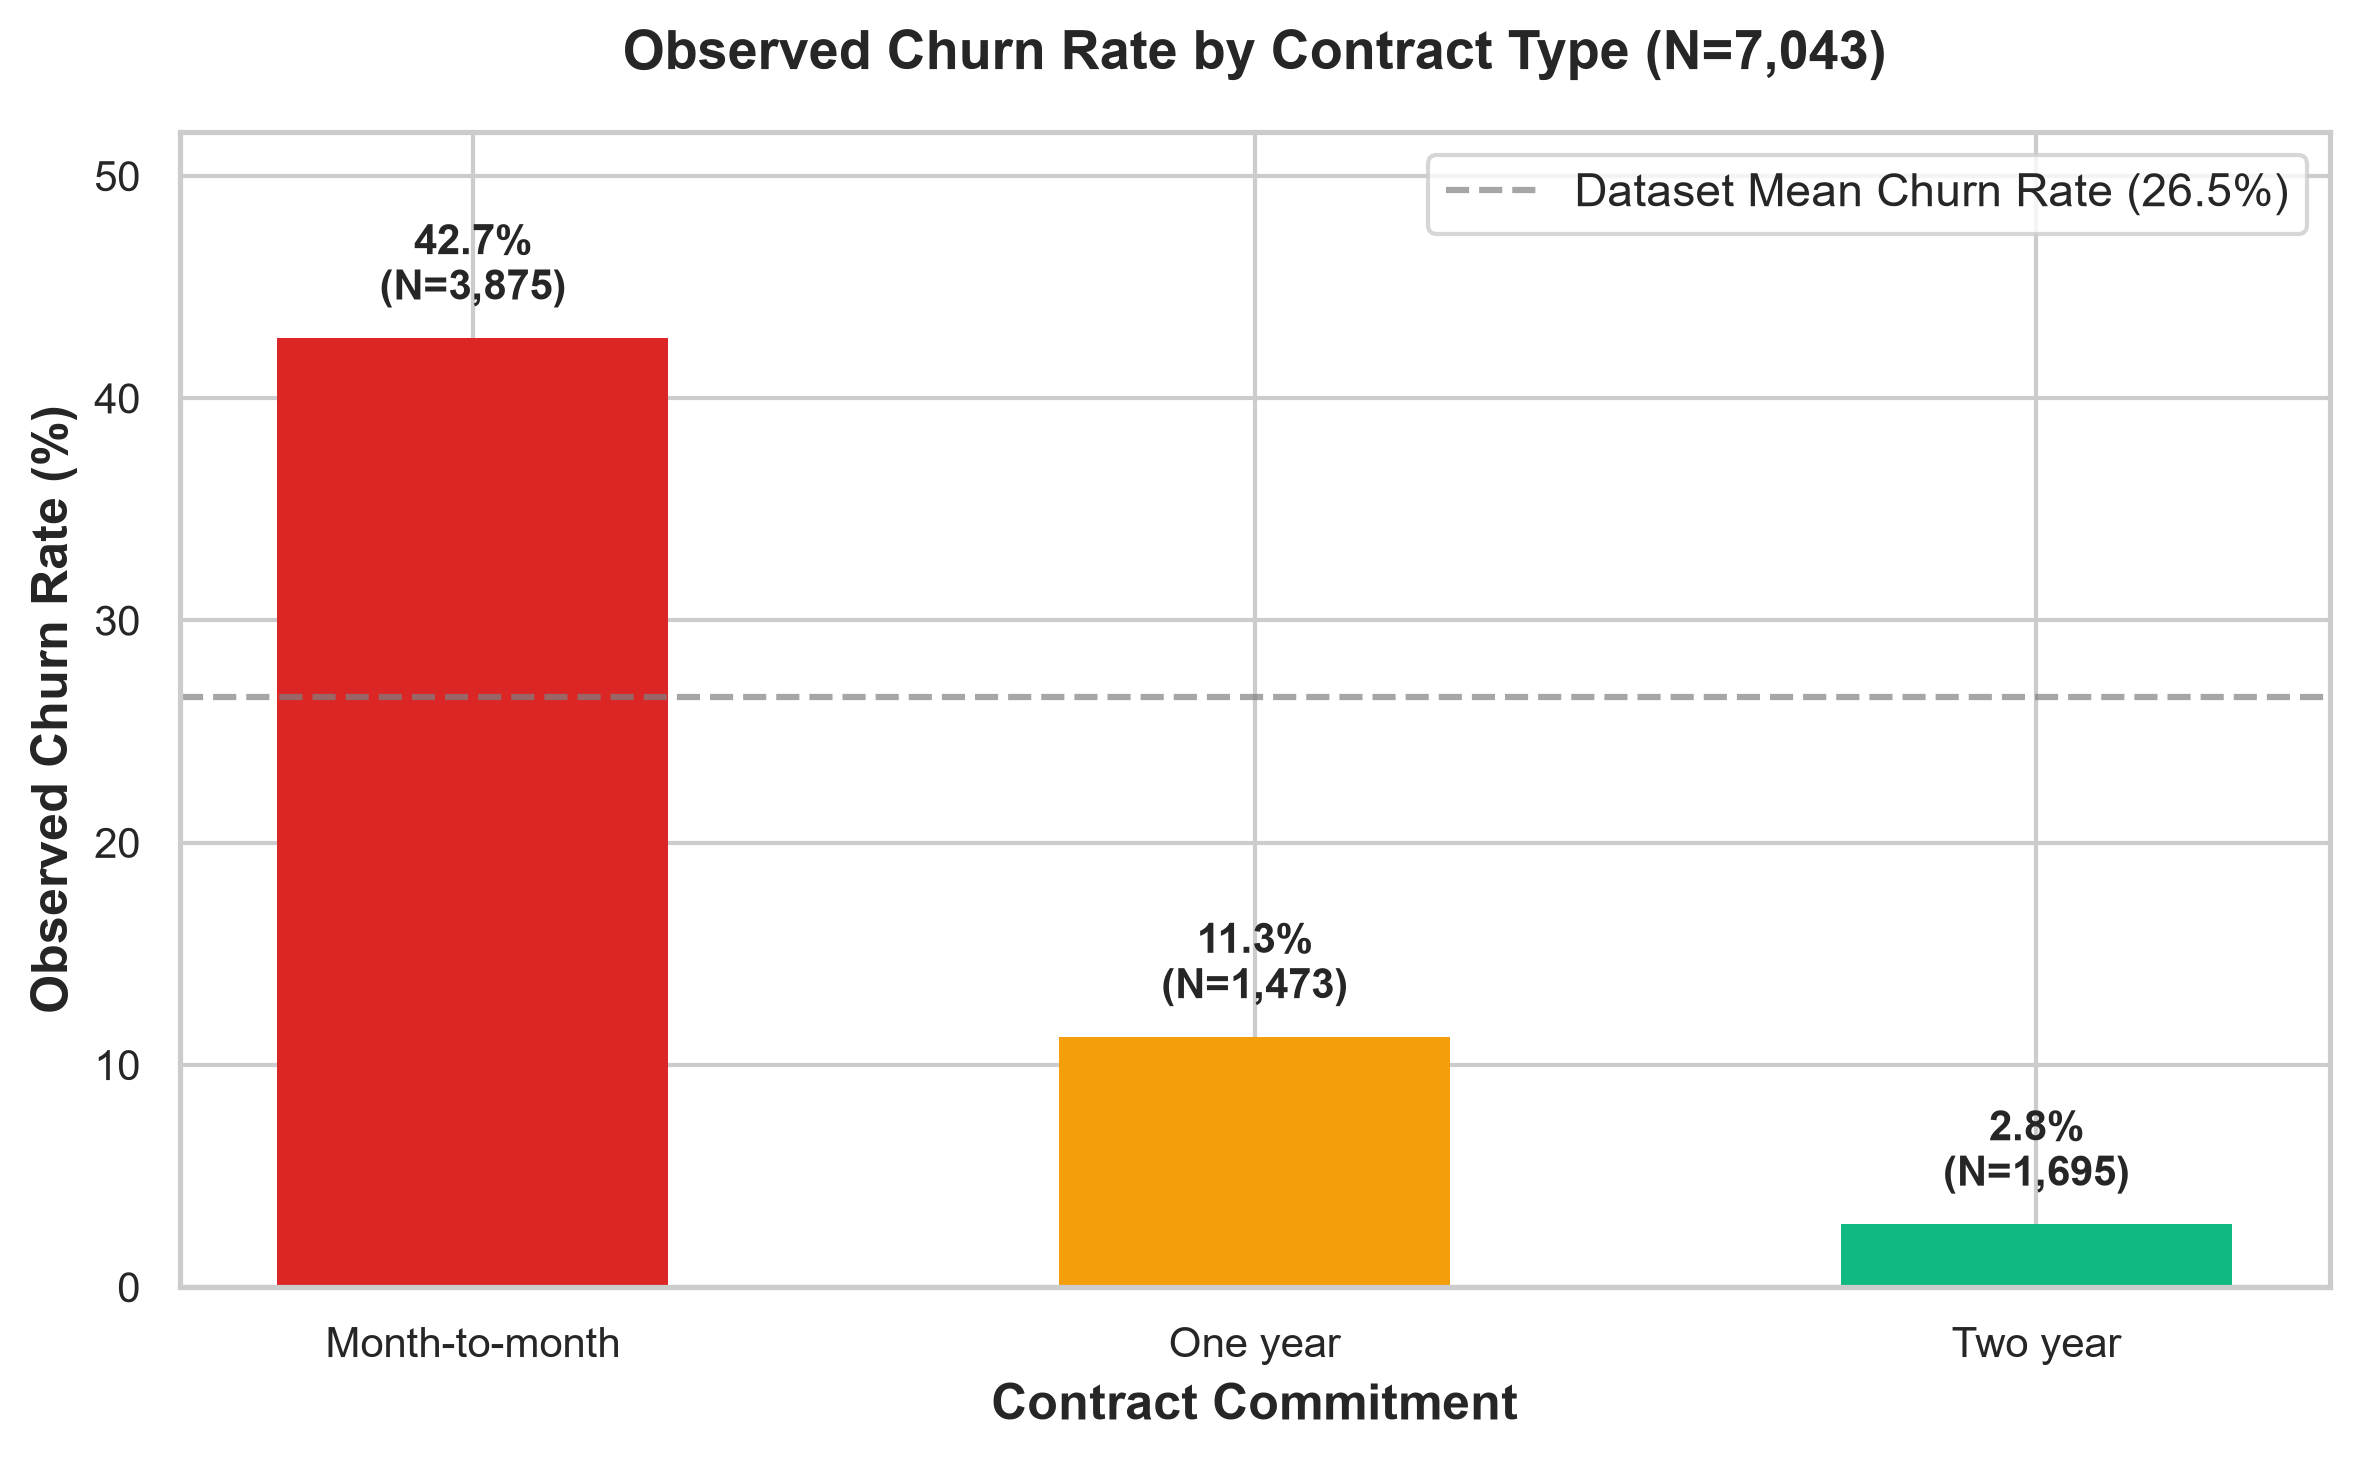


--- Churn Rate by Tenure Cohort ---


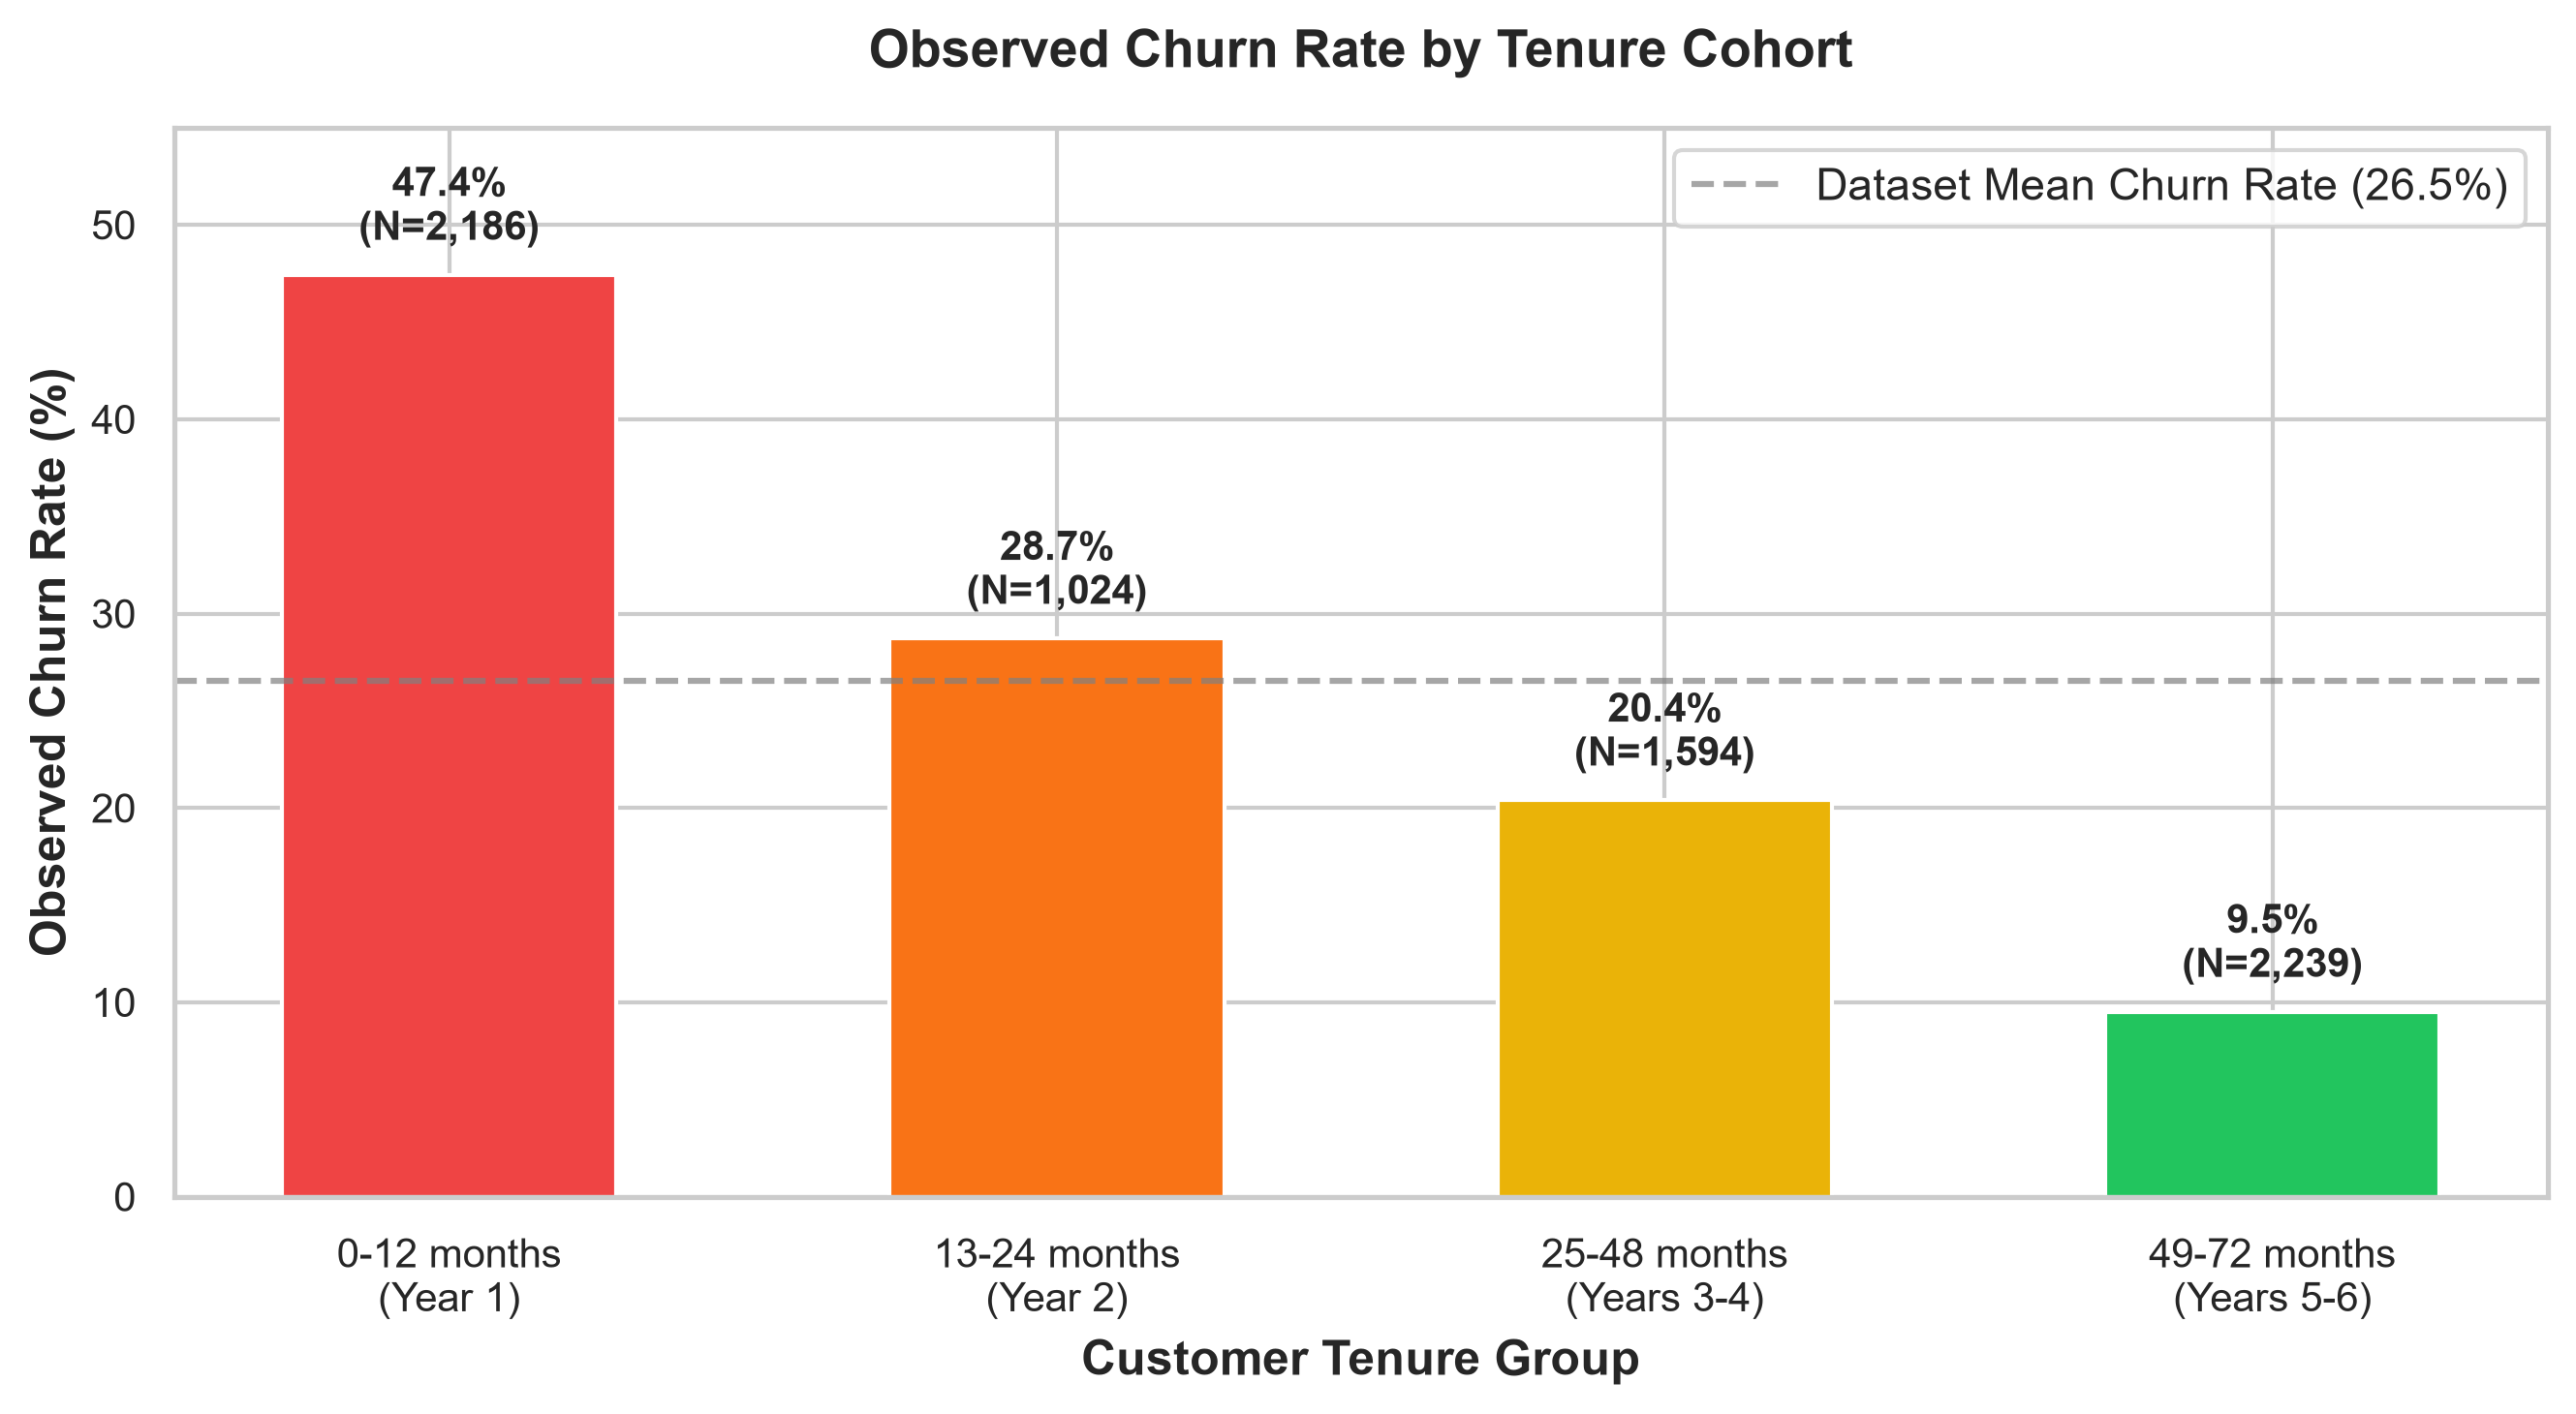


--- Monthly Charges Distribution and Churn ---


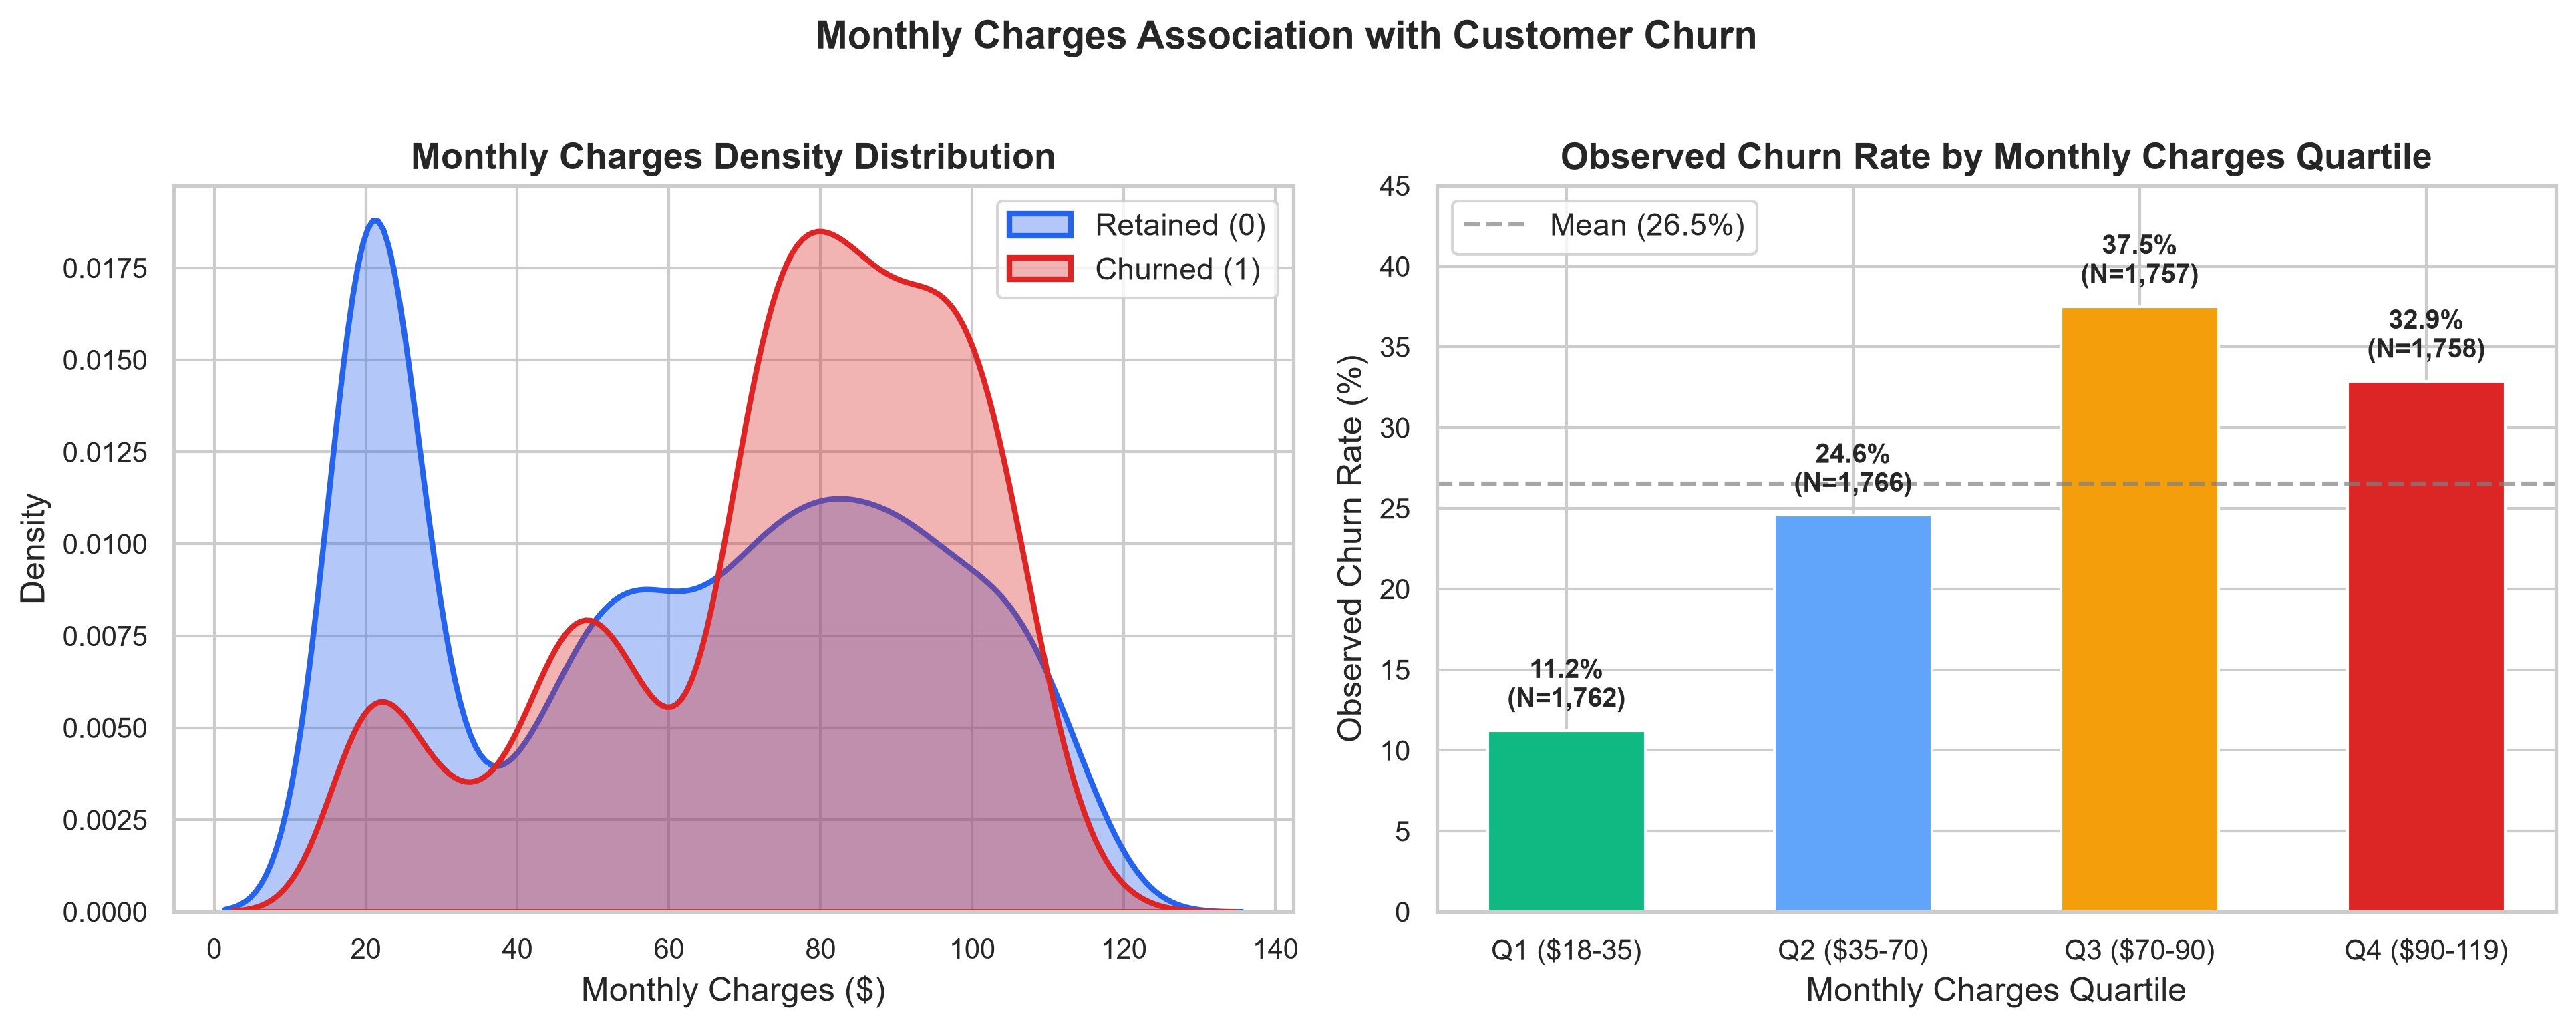


--- Churn by Service & Payment Attributes ---


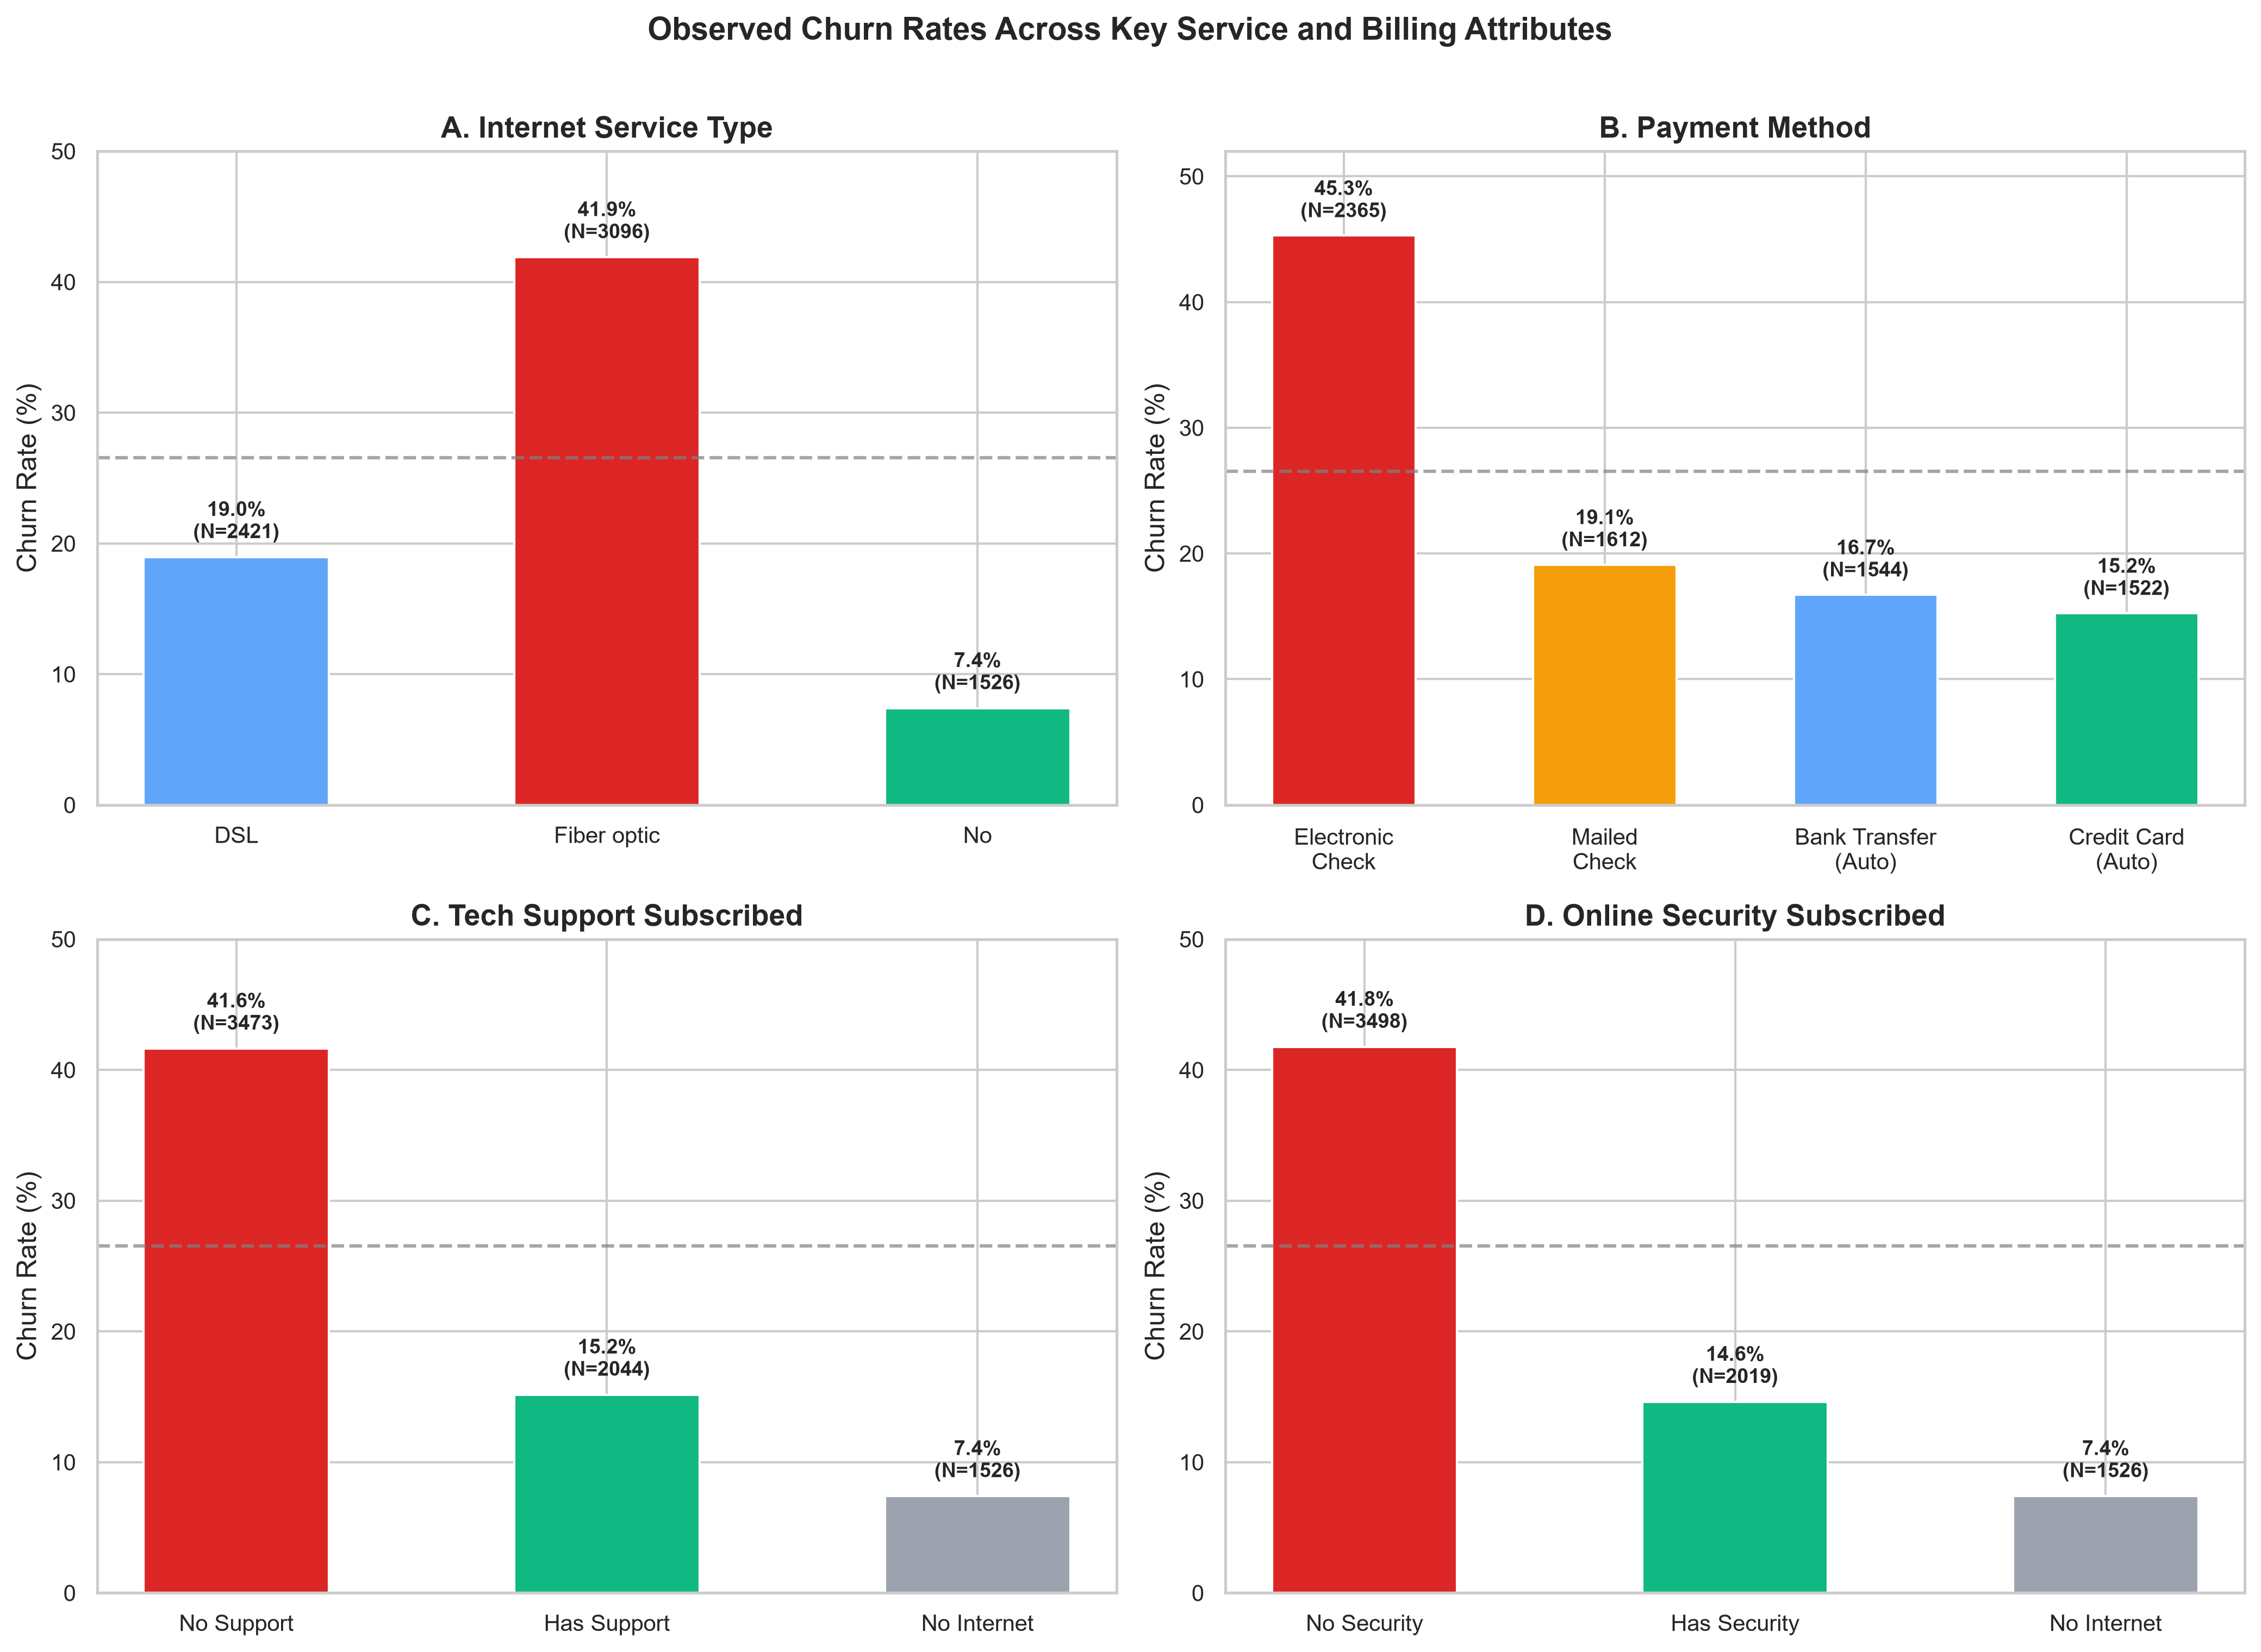


--- Baseline Model Feature Drivers ---


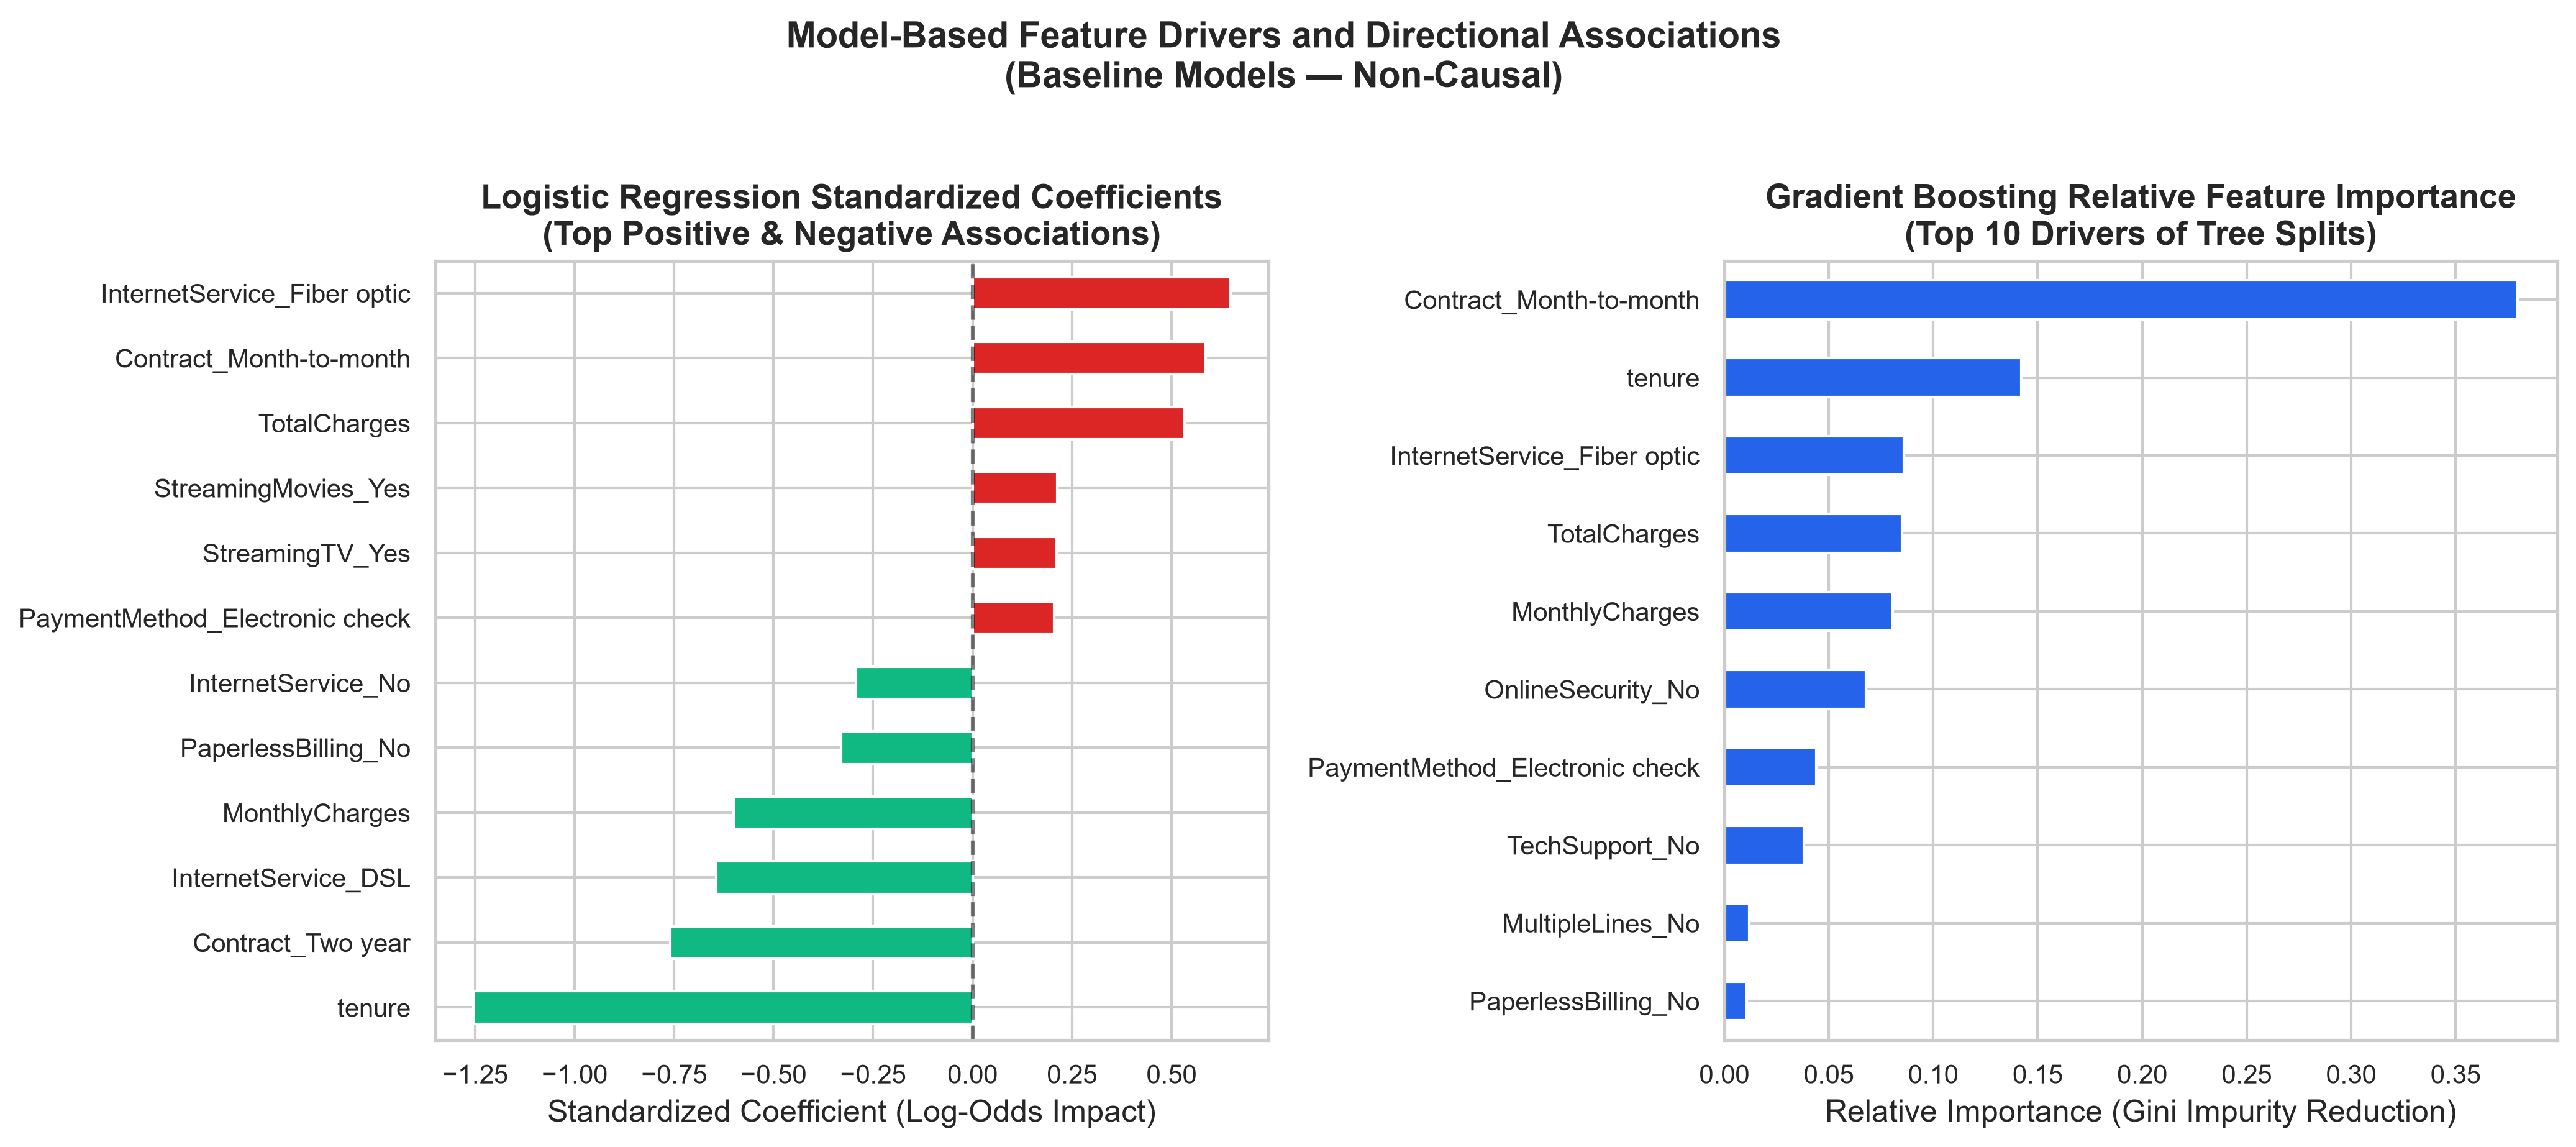

In [7]:
# Display generated figures
from IPython.display import Image, display

figures = [
    ("Churn Rate by Contract Type", "../reports/figures/churn_by_contract_type.png"),
    ("Churn Rate by Tenure Cohort", "../reports/figures/churn_by_tenure_group.png"),
    ("Monthly Charges Distribution and Churn", "../reports/figures/churn_by_monthly_charges.png"),
    ("Churn by Service & Payment Attributes", "../reports/figures/churn_by_service_attributes.png"),
    ("Baseline Model Feature Drivers", "../reports/figures/feature_importance_baseline.png"),
]

for title, path in figures:
    if not os.path.exists(path):
        # Fallback to direct path if running from root
        path = path.replace("../", "")
    print(f"\n--- {title} ---")
    display(Image(filename=path, width=750))


## 6. Business Interpretation, Descriptive Risk Profiles & Limitations

### Descriptive Customer Risk Profiles

- **Observed High-Risk Segment Profile ("Flight Risk"):** A descriptive profile characterized by accounts in their first 12 months on a month-to-month contract, subscribing to Fiber Optic internet, paying by electronic check, with monthly charges $\ge \$70$, and without online security or tech support.
- **Observed Low-Risk Segment Profile ("Anchored"):** A descriptive profile characterized by accounts with $\ge 4$ years of tenure on a one- or two-year agreement, using automated payment (ACH/credit card), enrolled in support/security bundles, and paying moderate fees.

> **Observational Disclaimer:** These segment profiles are descriptive, dataset-based risk patterns reflecting historical associations. They do not represent causal conclusions, nor do they constitute operational retention recommendations (which are reserved for later phases).

---

### What Baseline Modeling Results Reveal About the Churn Problem
1. **Strong Separation Signal Exists:** Linear models (Logistic Regression, ROC-AUC $0.8420$) and gradient boosted ensembles (Gradient Boosting, ROC-AUC $0.8433$) achieve robust discrimination. The feature set captures meaningful statistical signal distinguishing churners from retained customers.
2. **Threshold Sensitivity:** At the default 0.5 classification threshold, the baseline models missed approximately 44%–52% of actual churners in the hold-out test set. This indicates that threshold choice may materially affect the recall/business tradeoff and can be investigated in a later phase.


---

### Important Limitations and Sources of Uncertainty
1. **Observational & Cross-Sectional Data:** The dataset represents a historical snapshot without longitudinal event sequences. We cannot observe how customer sentiment evolved or how usage patterns changed leading up to cancellation.
2. **Non-Causal Associations:** Correlation is not causality. For example, Fiber optic subscribers exhibit higher churn rates, but this does not imply Fiber technology itself causes dissatisfaction. Fiber customers may be power users with higher service sensitivity, or competitors in urban fiber areas may offer aggressive promotional switching discounts.
3. **Unobserved Variables:** The dataset lacks critical operational context such as customer service complaint logs, network downtime records, competitor pricing in the customer's geographic area, and customer satisfaction scores (CSAT/NPS).
4. **Baseline Modeling State:** Models tested here are un-tuned baselines evaluated at a default cutoff. Model tuning, class re-balancing, and probability calibration have not yet been performed.
5. **Phase Boundary:** No retention intervention strategies or automated recommendation engines are created at this phase.


In [8]:
# Phase 5 Automated Validation Suite
checks = {
    "Baseline comparison CSV exists and has 5 models": os.path.exists(comparison_csv_path) and len(comparison_df) == 5,
    "Figure: churn_by_contract_type.png exists": os.path.exists(os.path.join(project_root, "reports", "figures", "churn_by_contract_type.png")),
    "Figure: churn_by_tenure_group.png exists": os.path.exists(os.path.join(project_root, "reports", "figures", "churn_by_tenure_group.png")),
    "Figure: churn_by_monthly_charges.png exists": os.path.exists(os.path.join(project_root, "reports", "figures", "churn_by_monthly_charges.png")),
    "Figure: churn_by_service_attributes.png exists": os.path.exists(os.path.join(project_root, "reports", "figures", "churn_by_service_attributes.png")),
    "Figure: feature_importance_baseline.png exists": os.path.exists(os.path.join(project_root, "reports", "figures", "feature_importance_baseline.png")),
    "Test set ground truth matches (N=1409, churn=374)": len(y_test) == 1409 and int(y_test.sum()) == 374,
    "Confusion matrix records generated for all 5 models": len(cm_df) == 5,
}

print("Phase 5 Automated Validation Results:")
print("=" * 65)
for name, status in checks.items():
    print(f"• {name:<55}: {'PASSED' if status else 'FAILED'}")
print("=" * 65)

assert all(checks.values()), "Phase 5 validation suite failed!"
print("All Phase 5 validation assertions passed successfully.")


Phase 5 Automated Validation Results:
• Baseline comparison CSV exists and has 5 models        : PASSED
• Figure: churn_by_contract_type.png exists              : PASSED
• Figure: churn_by_tenure_group.png exists               : PASSED
• Figure: churn_by_monthly_charges.png exists            : PASSED
• Figure: churn_by_service_attributes.png exists         : PASSED
• Figure: feature_importance_baseline.png exists         : PASSED
• Test set ground truth matches (N=1409, churn=374)      : PASSED
• Confusion matrix records generated for all 5 models    : PASSED
All Phase 5 validation assertions passed successfully.
